# Notebook 3: Fine-tuning DistilBERT

**Project:** Sentiment Analysis of E-Commerce Reviews: Classical ML vs. Transformer (DistilBERT)

**What this notebook does**

1. Loads the same train / validation / test splits as Notebook 2.
2. Measures review length in **tokens** and chooses the maximum input length.
3. Fine-tunes the pre-trained **DistilBERT** (`distilbert-base-uncased`) to predict negative / neutral / positive.
4. Tries a few training settings and keeps the one with the best **validation macro-F1** (the same rule as Notebook 2).
5. Saves the fine-tuned model to `models/distilbert/` for Phase 4 (evaluation) and Phase 5 (web app).

**The test split is NOT used here**, exactly as in Notebook 2.

**You need a GPU.** On Colab: `Runtime > Change runtime type > T4 GPU` *before* running.
Training takes roughly 1-2 hours for all settings together (measured: about 7 minutes per epoch on a GTX 1650 laptop GPU).
On a CPU it would take many hours.

## Step 1: Set up the project folder

Same as Notebooks 1 and 2.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # >>> Change this line ONLY if you put the project folder somewhere else in your Drive <<<
    PROJECT_DIR = Path("/content/drive/MyDrive/ecommerce-sentiment-analysis")
else:
    # Running on your own computer: this notebook lives in <project>/notebooks/
    here = Path.cwd()
    PROJECT_DIR = here.parent if here.name == "notebooks" else here

if not (PROJECT_DIR / "src" / "config.py").exists():
    raise FileNotFoundError(
        f"Could not find the project at {PROJECT_DIR}.\n"
        "Check that the folder 'ecommerce-sentiment-analysis' (containing 'src', 'notebooks', ...) "
        "is in the place named above, or edit PROJECT_DIR."
    )

os.chdir(PROJECT_DIR)                      # work from the project root
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))   # lets us write: from src import config
print("Project folder:", PROJECT_DIR)

Project folder: C:\Users\chand\Downloads\ecommerce-sentiment-analysis-phase1\ecommerce-sentiment-analysis


## Step 2: Import libraries and check the GPU

Colab already has `torch` and `transformers`. On your own computer install them first (see `requirements.txt`).

In [2]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import transformers
from sklearn.metrics import classification_report, confusion_matrix

from src import config as C
from src import data_preprocessing as dp
from src import transformer_model as tm

C.ensure_dirs()
# Hide the long "newly initialised classifier weights" report printed for every run; that is expected here
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

PALETTE = {"negative": "#C44E52", "neutral": "#8C8C8C", "positive": "#55A868"}

def savefig(name):
    """Save the current figure into results/figures/ (used later in the report)."""
    path = C.FIGURES_DIR / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path.relative_to(C.PROJECT_DIR))

device = tm.get_device()
print("torch", torch.__version__, "| transformers", transformers.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)",
          "| mixed precision:", tm.use_mixed_precision(device))
else:
    print("WARNING: no GPU found. Training will be VERY slow. On Colab: Runtime > Change runtime type > T4 GPU.")

torch 2.14.1+cu126 | transformers 5.21.0
GPU: NVIDIA GeForce GTX 1650 (4.3 GB) | mixed precision: False


## Step 3: Load the splits from Notebook 1

In [3]:
train, val, test = dp.load_splits()
for name, split in (("train", train), ("val", val), ("test", test)):
    print(f"{name:<5} {len(split):>6} reviews")
# `test` is loaded only to show its size. It is not used again in this notebook.

train  15843 reviews
val     3395 reviews
test    3395 reviews


## Step 4: Tokens, and how long a review may be

DistilBERT does not read words; it reads **tokens** (whole words or pieces of words, e.g. *"unflattering"* becomes
*"un", "##fl", "##atter", "##ing"*). It can read at most 512 tokens, but longer inputs cost more time and memory,
so we choose a limit that fits almost every review. Anything longer is cut off at the end.

Notebook 1 counted at most 115 *words* per review; tokens are usually a bit more than words.

Example: ['this', 'top', 'is', 'un', '##fl', '##atter', '##ing', 'and', 'not', 'worth', 'the', 'price', '.']


,tokens per review
count,15843.0
mean,76.7
std,35.4
min,4.0
50%,75.0
90%,124.0
95%,129.0
99%,136.0
max,154.0


Reviews longer than  64 tokens: 58.72%
Reviews longer than 128 tokens:  5.07%
Reviews longer than 160 tokens:  0.00%
Reviews longer than 256 tokens:  0.00%


Saved: results\figures\token_length.png


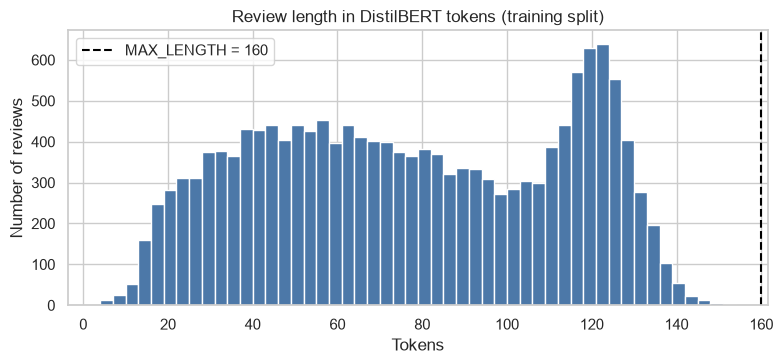

In [4]:
tokenizer = tm.load_tokenizer()
print("Example:", tokenizer.tokenize("This top is unflattering and not worth the price."))

lengths = tm.token_lengths(tokenizer, train[C.TEXT_COL])
display(pd.Series(lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1).to_frame("tokens per review"))
for limit in (64, 128, C.MAX_LENGTH, 256):
    print(f"Reviews longer than {limit:>3} tokens: {(lengths > limit).mean() * 100:5.2f}%")

plt.figure(figsize=(8, 3.8))
plt.hist(lengths, bins=50, color="#4C78A8")
plt.axvline(C.MAX_LENGTH, color="black", linestyle="--", label=f"MAX_LENGTH = {C.MAX_LENGTH}")
plt.title("Review length in DistilBERT tokens (training split)")
plt.xlabel("Tokens"); plt.ylabel("Number of reviews"); plt.legend()
plt.tight_layout()
savefig("token_length.png")
plt.show()

**Decision:** `MAX_LENGTH` (set in `src/config.py`) covers almost every review, so practically no text is cut off.
Batches are padded only up to their own longest review, so short reviews do not waste time.

## Step 5: Prepare the data for PyTorch

Each review is turned into token ids once, up front.

In [5]:
start = time.time()
train_ds = tm.ReviewDataset(train[C.TEXT_COL], train[C.LABEL_ID_COL], tokenizer)
val_ds = tm.ReviewDataset(val[C.TEXT_COL], val[C.LABEL_ID_COL], tokenizer)
print(f"Tokenised {len(train_ds)} training and {len(val_ds)} validation reviews in {time.time() - start:.1f}s")
print("Class weights (used only when class_weighted=True):",
      dict(zip(C.LABEL_NAMES, tm.balanced_class_weights(train_ds.labels).numpy().round(2))))

Tokenised 15843 training and 3395 validation reviews in 2.0s
Class weights (used only when class_weighted=True): {'negative': np.float32(3.19), 'neutral': np.float32(2.67), 'positive': np.float32(0.43)}


## Step 6: Fine-tune DistilBERT

**What fine-tuning means:** DistilBERT has already learned English from millions of sentences. We add a small new
output layer with 3 outputs (negative / neutral / positive) and train the *whole* network a little more on our reviews.

**Fixed settings** (standard values for BERT-style models; see `TRAIN_DEFAULTS` in `src/transformer_model.py`):

| Setting | Value | Meaning |
|---|---|---|
| epochs | up to 4 | one epoch = one pass over all training reviews |
| batch size | 16 | reviews processed together in one step |
| warm-up | 10% of steps | learning rate starts at 0 and rises, so the new output layer does not damage the pre-trained weights early on |
| weight decay | 0.01 | mild regularisation |
| early stopping | patience 2 | stop if validation macro-F1 does not improve for 2 epochs |

**Settings we try** (`SEARCH_GRID`): learning rate {2e-5, 5e-5} x class weighting {off, on} = 4 runs.
Class weighting is the transformer version of `class_weight="balanced"`, which helped every model in Notebook 2.

After **every epoch** the model is scored on validation, and the weights of the best epoch are kept.
That is how we decide *when to stop training*, using validation data only.

This cell is the slow one. Progress is printed after every epoch, and also written to
`results/distilbert_training_log.txt` (useful if the browser tab disconnects).

In [6]:
log_path = C.RESULTS_DIR / "distilbert_training_log.txt"
log_path.write_text("")

def log(message):
    print(message, flush=True)
    with open(log_path, "a") as f:
        f.write(message + "\n")

results, history, best_run = tm.search(train_ds, val_ds, tokenizer, device=device, log=log)

print("\nAll runs (best epoch of each), sorted by validation macro-F1:")
display(results.round(3))
best_settings = {k: best_run["settings"][k] for k in tm.SEARCH_GRID}
print("Best settings:", best_settings, "| best epoch:", best_run["best_epoch"])

Run 1/4: {'learning_rate': 2e-05, 'class_weighted': False}


  epoch 1: train loss 0.4885 | val accuracy 0.833 | val macro-F1 0.606 | 8.5 min


  epoch 2: train loss 0.3220 | val accuracy 0.846 | val macro-F1 0.664 | 20.6 min


  epoch 3: train loss 0.2409 | val accuracy 0.839 | val macro-F1 0.653 | 30.8 min


  epoch 4: train loss 0.1783 | val accuracy 0.841 | val macro-F1 0.657 | 39.6 min


...

  epoch 3: train loss 0.4165 | val accuracy 0.815 | val macro-F1 0.655 | 25.4 min


  epoch 4: train loss 0.2565 | val accuracy 0.832 | val macro-F1 0.663 | 33.8 min



All runs (best epoch of each), sorted by validation macro-F1:


,run,learning_rate,class_weighted,best_epoch,minutes,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,2,2e-05,True,4,60.3,0.828,0.668,0.839,0.619,0.453,0.931
1,3,5e-05,False,3,43.6,0.844,0.665,0.844,0.615,0.439,0.941
2,1,2e-05,False,2,39.6,0.846,0.664,0.845,0.591,0.460,0.941
3,4,5e-05,True,4,33.8,0.832,0.663,0.839,0.602,0.453,0.934


Best settings: {'learning_rate': 2e-05, 'class_weighted': True} | best epoch: 4


## Step 7: Learning curves

* **Left:** training loss should go down every epoch.
* **Right:** validation macro-F1. If it peaks and then falls, the model started to *overfit* (memorise the training reviews);
  that is why we keep the best epoch, not the last one.

Saved: results\figures\distilbert_learning_curves.png


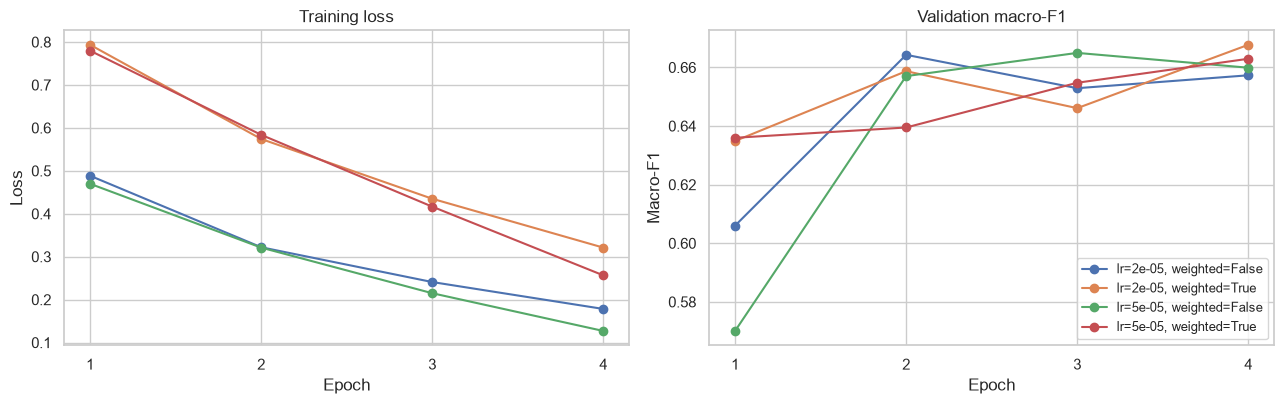

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for run_id, part in history.groupby("run"):
    label = f"lr={part['learning_rate'].iloc[0]}, weighted={part['class_weighted'].iloc[0]}"
    axes[0].plot(part["epoch"], part["train_loss"], marker="o", label=label)
    axes[1].plot(part["epoch"], part["macro_f1"], marker="o", label=label)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for ax in axes:
    ax.set_xticks(sorted(history["epoch"].unique()))
axes[1].legend(fontsize=9)
plt.tight_layout()
savefig("distilbert_learning_curves.png")
plt.show()

## Step 8: The best DistilBERT on the validation split

We put it next to the three classical models from Notebook 2 (also validation scores).
This is only a first look; the real comparison, on the untouched test split, is Phase 4.

,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
model,,,,,,
DistilBERT,0.828,0.668,0.839,0.619,0.453,0.931
Naive Bayes,0.827,0.652,0.832,0.567,0.460,0.929
Logistic Regression,0.830,0.640,0.829,0.570,0.420,0.930
Linear SVM,0.835,0.638,0.830,0.572,0.410,0.933
Majority baseline,0.770,0.290,0.671,0.000,0.000,0.870


              precision    recall  f1-score   support

    negative      0.598     0.640     0.619       356
     neutral      0.398     0.527     0.453       423
    positive      0.962     0.902     0.931      2616

    accuracy                          0.828      3395
   macro avg      0.653     0.690     0.668      3395
weighted avg      0.854     0.828     0.839      3395



Saved: results\figures\distilbert_confusion_val.png


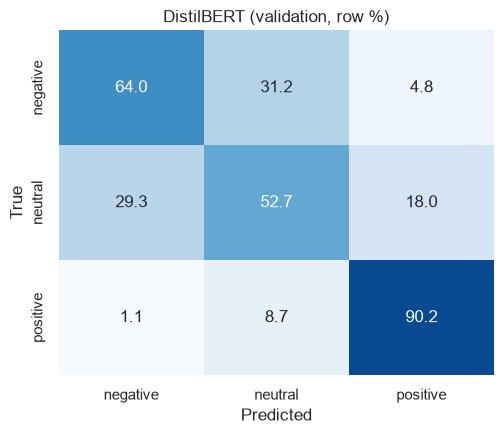

In [8]:
best_metrics = best_run["best_metrics"]
comparison = pd.read_csv(C.RESULTS_DIR / "classical_val_results.csv", index_col="model")
comparison.loc[C.TRANSFORMER_DISPLAY_NAME] = best_metrics
comparison = comparison.sort_values(C.SELECTION_METRIC, ascending=False)
display(comparison.round(3))

# Re-create the best model from its saved weights to get its predictions
model = tm.load_pretrained_model()
model.load_state_dict(best_run["best_state"])
model.to(device)
val_pred = tm.predict_logits(model, tm.make_loader(val_ds, tokenizer, 64, shuffle=False), device).argmax(axis=1)
y_val = val[C.LABEL_ID_COL].to_numpy()

print(classification_report(y_val, val_pred, target_names=C.LABEL_NAMES, digits=3))

cmat = confusion_matrix(y_val, val_pred, normalize="true") * 100
plt.figure(figsize=(5.2, 4.5))
sns.heatmap(cmat, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar=False,
            xticklabels=C.LABEL_NAMES, yticklabels=C.LABEL_NAMES)
plt.title("DistilBERT (validation, row %)"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
savefig("distilbert_confusion_val.png")
plt.show()

## Step 9: Save the model and the results

The model is saved in the standard Hugging Face format (`config.json`, `model.safetensors`, tokenizer files),
so it can be loaded again with one line.

In [9]:
out_dir = tm.save_model(best_run["best_state"], tokenizer)
size_mb = sum(p.stat().st_size for p in out_dir.iterdir()) / 1e6
print(f"Saved: {out_dir.relative_to(C.PROJECT_DIR)}  ({size_mb:.0f} MB)")

results.round(4).to_csv(C.RESULTS_DIR / "distilbert_search.csv", index=False)
history.round(4).to_csv(C.RESULTS_DIR / "distilbert_history.csv", index=False)

summary = {
    "model": C.TRANSFORMER_NAME,
    "selection_metric": C.SELECTION_METRIC,
    "selection_split": "val",
    "max_length": C.MAX_LENGTH,
    "share_truncated_train": float((lengths > C.MAX_LENGTH).mean()),
    "train_defaults": tm.TRAIN_DEFAULTS,
    "search_grid": tm.SEARCH_GRID,
    "best_settings": best_settings,
    "best_epoch": best_run["best_epoch"],
    "val_metrics": best_metrics,
    "total_training_minutes": round(float(results["minutes"].sum()), 1),
    "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "library_versions": {"torch": torch.__version__, "transformers": transformers.__version__},
}
summary_path = C.RESULTS_DIR / "distilbert_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)
print("Saved:", summary_path.relative_to(C.PROJECT_DIR))
print("Saved:", (C.RESULTS_DIR / "distilbert_search.csv").relative_to(C.PROJECT_DIR))
print("Saved:", (C.RESULTS_DIR / "distilbert_history.csv").relative_to(C.PROJECT_DIR))

Saved: models\distilbert  (269 MB)
Saved: results\distilbert_summary.json
Saved: results\distilbert_search.csv
Saved: results\distilbert_history.csv


## Step 10: Final check (the Phase 3 checklist)

This cell reloads the model **from disk**, exactly as Phase 4 and the web app will, and checks that it
gives the same validation scores and can classify brand-new sentences.

In [10]:
del model
tok2, model2 = tm.load_model(device=device)
pred2, _ = tm.predict_texts(val[C.TEXT_COL].tolist(), tok2, model2)
reloaded = tm.compute_metrics(y_val, pred2)
print(f"Validation macro-F1 after reload: {reloaded['macro_f1']:.4f} (before saving: {best_metrics['macro_f1']:.4f})")
# Tiny differences can come from half-precision maths on the GPU, so allow a small tolerance
assert abs(reloaded["macro_f1"] - best_metrics["macro_f1"]) < 0.005, "Scores changed after reload"
assert reloaded["macro_f1"] > 0.29, "Does not beat the majority baseline"

examples = [
    "I love this dress, it fits perfectly and the colour is beautiful.",
    "The fabric feels cheap and it fell apart after one wash. Returning it.",
    "It's okay. Nice colour but it runs small and the material is a bit thin.",
    "Not good at all.",
]
pred, probs = tm.predict_texts(examples, tok2, model2)
display(pd.DataFrame({
    "prediction": [C.ID2LABEL[i] for i in pred],
    **{f"P({name})": probs[:, i].round(3) for i, name in enumerate(C.LABEL_NAMES)},
}, index=examples))

for name in ("distilbert_summary.json", "distilbert_search.csv", "distilbert_history.csv"):
    assert (C.RESULTS_DIR / name).exists()
assert (C.TRANSFORMER_DIR / "config.json").exists()

print("\nALL PHASE 3 CHECKS PASSED")

Validation macro-F1 after reload: 0.6677 (before saving: 0.6677)


,prediction,P(negative),P(neutral),P(positive)
"I love this dress, it fits perfectly and the colour is beautiful.",positive,0.003,0.004,0.993
The fabric feels cheap and it fell apart after one wash. Returning it.,negative,0.991,0.007,0.002
It's okay. Nice colour but it runs small and the material is a bit thin.,neutral,0.018,0.913,0.069
Not good at all.,negative,0.991,0.007,0.003



ALL PHASE 3 CHECKS PASSED


## Phase 3 complete

**Files this notebook created**

* `models/distilbert/` (fine-tuned weights + tokenizer)
* `results/distilbert_summary.json`, `distilbert_search.csv`, `distilbert_history.csv`
* `results/figures/token_length.png`, `distilbert_learning_curves.png`, `distilbert_confusion_val.png`

**Next (Phase 4):** load all four saved models, score each **once** on the untouched test split, and compare them
(macro-F1, per-class F1, confusion matrices, speed and model size).

*Write down for your report:* the chosen MAX_LENGTH and why, the best settings and epoch, the training time and GPU,
and how DistilBERT's validation scores compare with the classical models.